In [ ]:
!pip install yfinance pyarrow

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

from datetime import datetime
import json
import os

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("YFinance version:", yf.__version__)

Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
YFinance version: 0.2.66


# **Task 1.1**

In [ ]:
import requests
import pandas as pd
from io import StringIO
from datetime import datetime

# Wikipedia source
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Create browser-like request headers
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36"
}

# Request the Wikipedia page
response = requests.get(
    url,
    headers=headers,
    timeout=30
)

# Check request status
response.raise_for_status()

# Extract tables using Pandas
tables = pd.read_html(StringIO(response.text))

# Find S&P 500 constituents table
sp500 = next(
    table for table in tables
    if "Symbol" in table.columns
)

# Extract company symbols
tickers = sp500["Symbol"].tolist()

# Record retrieval date
retrieval_date = datetime.now().strftime("%Y-%m-%d")

print("Retrieval Date:", retrieval_date)
print("Total companies:", len(tickers))

# Display first 10 tickers
print(tickers[:10])

Retrieval Date: 2026-11-22
Total companies: 503
['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [ ]:
yahoo_tickers = [
    ticker.replace(".", "-")
    for ticker in tickers
]

print("Original ticker:", tickers[:10])
print("Yahoo ticker:", yahoo_tickers[:10])

Original ticker: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']
Yahoo ticker: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [ ]:
start_date = "2021-01-01"
end_date = "2025-01-01"

benchmark = "^GSPC"

print("Start Date:", start_date)
print("End Date:", end_date)
print("Benchmark:", benchmark)

Start Date: 2021-01-01
End Date: 2025-01-01
Benchmark: ^GSPC


In [ ]:
# Combine stock tickers and benchmark
all_tickers = yahoo_tickers + [benchmark]

# Store downloaded stock data
stock_data = {}

# Download in batches
batch_size = 50

for i in range(0, len(all_tickers), batch_size):

    batch = all_tickers[i:i + batch_size]

    print(f"Downloading batch {i // batch_size + 1}")

    data = yf.download(
        batch,
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=False,
        actions=True,
        group_by="ticker",
        threads=True,
        progress=False
    )

    if data.empty:
        print("No data returned for this batch")
        continue

    # Separate data for each ticker
    if isinstance(data.columns, pd.MultiIndex):

        for ticker in batch:

            if ticker in data.columns.get_level_values(0):
                stock_data[ticker] = data[ticker].copy()

            elif ticker in data.columns.get_level_values(1):
                stock_data[ticker] = data.xs(
                    ticker,
                    axis=1,
                    level=1
                ).copy()

    else:
        if len(batch) == 1:
            stock_data[batch[0]] = data.copy()

print("Download completed.")
print("Successfully downloaded:", len(stock_data))

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Download completed.
Successfully downloaded: 504


In [ ]:
#Check the downloaded data
# Display Apple stock data
print(stock_data["AAPL"].head())

# Display Apple data columns
print("\nAvailable columns:")
print(stock_data["AAPL"].columns.tolist())

# Display S&P 500 benchmark data
print("\nS&P 500 Benchmark:")
print(stock_data["^GSPC"].head())

Price             Open        High         Low       Close   Adj Close  \
Date                                                                     
2021-01-04  133.520004  133.610001  126.760002  129.410004  125.537109   
2021-01-05  128.889999  131.740005  128.429993  131.009995  127.089249   
2021-01-06  127.720001  131.050003  126.379997  126.599998  122.811203   
2021-01-07  128.360001  131.630005  127.860001  130.919998  127.001938   
2021-01-08  132.429993  132.630005  130.229996  132.050003  128.098083   

Price          Volume  Dividends  Stock Splits  
Date                                            
2021-01-04  143301900        0.0           0.0  
2021-01-05   97664900        0.0           0.0  
2021-01-06  155088000        0.0           0.0  
2021-01-07  109578200        0.0           0.0  
2021-01-08  105158200        0.0           0.0  

Available columns:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']

S&P 500 Benchmark:
Price        

In [ ]:
#Identify unsuccessful downloads
downloaded_tickers = list(stock_data.keys())

failed_tickers = [
    ticker for ticker in all_tickers
    if ticker not in downloaded_tickers
]

print("Total requested:", len(all_tickers))
print("Successfully downloaded:", len(downloaded_tickers))
print("Failed downloads:", len(failed_tickers))

print("\nFailed ticker symbols:")
print(failed_tickers)

Total requested: 504
Successfully downloaded: 504
Failed downloads: 0

Failed ticker symbols:
[]


In [ ]:
#Save the downloaded data
# Create project folder
os.makedirs("CRM_Coursework_Data", exist_ok=True)

# Save ticker list
sp500.to_csv(
    "CRM_Coursework_Data/sp500_tickers.csv",
    index=False
)

# Combine downloaded stock data
combined_data = pd.concat(
    stock_data,
    names=["Ticker", "Date"]
)

# Save historical data
combined_data.to_parquet(
    "CRM_Coursework_Data/historical_stock_data.parquet"
)

# Save metadata
metadata = {
    "ticker_retrieval_date": retrieval_date,
    "data_download_date": datetime.now().strftime("%Y-%m-%d"),
    "start_date": start_date,
    "end_date_exclusive": end_date,
    "benchmark": benchmark,
    "data_source": "Yahoo Finance",
    "library": "yfinance",
    "yfinance_version": yf.__version__,
    "requested_tickers": len(all_tickers),
    "successfully_downloaded": len(downloaded_tickers),
    "failed_tickers": failed_tickers
}

with open(
    "CRM_Coursework_Data/download_metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("All available data and metadata saved successfully!")

All available data and metadata saved successfully!


In [ ]:
successful_tickers = [
    ticker for ticker, data in stock_data.items()
    if data is not None and not data.empty
]

failed_tickers = [
    ticker for ticker, data in stock_data.items()
    if data is None or data.empty
]

print("Successfully downloaded:", len(successful_tickers))
print("Failed downloads:", len(failed_tickers))
print("Failed ticker symbols:", failed_tickers)

Successfully downloaded: 504
Failed downloads: 0
Failed ticker symbols: []


# **Task 1.2**

In [ ]:
# Task 1.2 – Data Validation and Alignment

start_date = "2021-01-01"
end_date = "2025-01-01"
benchmark = "^GSPC"

# Separate benchmark data
benchmark_data = stock_data[benchmark].copy()

# Separate individual company data
company_data = {
    ticker: data.copy()
    for ticker, data in stock_data.items()
    if ticker != benchmark
}

# Restrict all data to the study period
for ticker in stock_data:

    data = stock_data[ticker].copy()

    data.index = pd.to_datetime(data.index)

    # Remove timezone information if present
    if data.index.tz is not None:
        data.index = data.index.tz_localize(None)

    data = data.sort_index()

    data = data[
        (data.index >= start_date) &
        (data.index < end_date)
    ]

    stock_data[ticker] = data

# Refresh separated datasets
benchmark_data = stock_data[benchmark].copy()

company_data = {
    ticker: data.copy()
    for ticker, data in stock_data.items()
    if ticker != benchmark
}

print("Companies:", len(company_data))
print("Benchmark observations:", len(benchmark_data))
print("Study period:", start_date, "to", end_date)

Companies: 503
Benchmark observations: 1005
Study period: 2021-01-01 to 2025-01-01


In [ ]:
duplicate_results = []

for ticker, data in stock_data.items():

    duplicate_count = data.index.duplicated().sum()

    duplicate_results.append({
        "Ticker": ticker,
        "Duplicate Dates": duplicate_count
    })

duplicate_df = pd.DataFrame(duplicate_results)

print("Total duplicate dates:",
      duplicate_df["Duplicate Dates"].sum())

display(duplicate_df.head(10))

Total duplicate dates: 0


,Ticker,Duplicate Dates
0,MMM,0
1,AOS,0
2,ABT,0
3,ABBV,0
4,ACN,0
5,ADBE,0
6,AMD,0
7,AES,0
8,AFL,0
9,A,0


In [ ]:
for ticker in stock_data:

    stock_data[ticker] = stock_data[ticker][
        ~stock_data[ticker].index.duplicated(keep="last")
    ].sort_index()

# Refresh company and benchmark data
benchmark_data = stock_data[benchmark].copy()

company_data = {
    ticker: data.copy()
    for ticker, data in stock_data.items()
    if ticker != benchmark
}

print("Duplicate date check completed.")

Duplicate date check completed.


In [ ]:
missing_results = []

for ticker, data in stock_data.items():

    for column in data.columns:

        missing_results.append({
            "Ticker": ticker,
            "Field": column,
            "Missing Values": data[column].isna().sum()
        })

missing_df = pd.DataFrame(missing_results)

print("Total missing values:",
      missing_df["Missing Values"].sum())

display(missing_df.head(20))

Total missing values: 63638


,Ticker,Field,Missing Values
0,MMM,Open,0
1,MMM,High,0
2,MMM,Low,0
3,MMM,Close,0
4,MMM,Adj Close,0
5,MMM,Volume,0
6,MMM,Dividends,0
7,MMM,Stock Splits,0
8,AOS,Open,0
9,AOS,High,0


In [ ]:
#Check non-positive prices and invalid volumes
price_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Adj Close"
]

invalid_results = []

for ticker, data in stock_data.items():

    for column in price_columns:

        if column in data.columns:

            invalid_count = (
                data[column].notna() &
                (data[column] <= 0)
            ).sum()

            invalid_results.append({
                "Ticker": ticker,
                "Field": column,
                "Invalid Values": invalid_count
            })

    if "Volume" in data.columns:

        negative_volume = (
            data["Volume"].notna() &
            (data["Volume"] < 0)
        ).sum()

        invalid_results.append({
            "Ticker": ticker,
            "Field": "Negative Volume",
            "Invalid Values": negative_volume
        })

invalid_df = pd.DataFrame(invalid_results)

print("Total invalid values:",
      invalid_df["Invalid Values"].sum())

display(invalid_df.head(20))

Total invalid values: 0


,Ticker,Field,Invalid Values
0,MMM,Open,0
1,MMM,High,0
2,MMM,Low,0
3,MMM,Close,0
4,MMM,Adj Close,0
5,MMM,Negative Volume,0
6,AOS,Open,0
7,AOS,High,0
8,AOS,Low,0
9,AOS,Close,0


In [ ]:
#Examine historical data coverage
coverage_results = []

for ticker, data in company_data.items():

    prices = data["Adj Close"].dropna()

    coverage_results.append({
        "Ticker": ticker,
        "Available Observations": len(prices),
        "First Available Date": (
            prices.index.min() if not prices.empty else None
        ),
        "Last Available Date": (
            prices.index.max() if not prices.empty else None
        ),
        "Missing Observations": data["Adj Close"].isna().sum()
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df.head(20))

print("Companies examined:", len(coverage_df))

,Ticker,Available Observations,First Available Date,Last Available Date,Missing Observations
0,MMM,1005,2021-01-04,2024-12-31,0
1,AOS,1005,2021-01-04,2024-12-31,0
2,ABT,1005,2021-01-04,2024-12-31,0
3,ABBV,1005,2021-01-04,2024-12-31,0
4,ACN,1005,2021-01-04,2024-12-31,0
5,ADBE,1005,2021-01-04,2024-12-31,0
6,AMD,1005,2021-01-04,2024-12-31,0
7,AES,1005,2021-01-04,2024-12-31,0
8,AFL,1005,2021-01-04,2024-12-31,0
9,A,1005,2021-01-04,2024-12-31,0


Companies examined: 503


In [ ]:
#Examine dividends and stock splits
corporate_actions_results = []

for ticker, data in stock_data.items():

    dividend_events = (
        (data["Dividends"] > 0).sum()
        if "Dividends" in data.columns else np.nan
    )

    split_events = (
        (data["Stock Splits"] > 0).sum()
        if "Stock Splits" in data.columns else np.nan
    )

    corporate_actions_results.append({
        "Ticker": ticker,
        "Dividend Events": dividend_events,
        "Stock Split Events": split_events
    })

corporate_actions_df = pd.DataFrame(
    corporate_actions_results
)

display(corporate_actions_df.head(20))

print("Total dividend events:",
      corporate_actions_df["Dividend Events"].sum())

print("Total stock split events:",
      corporate_actions_df["Stock Split Events"].sum())

,Ticker,Dividend Events,Stock Split Events
0,MMM,16.0,1.0
1,AOS,16.0,0.0
2,ABT,16.0,0.0
3,ABBV,16.0,0.0
4,ACN,16.0,0.0
5,ADBE,0.0,0.0
6,AMD,0.0,0.0
7,AES,16.0,0.0
8,AFL,16.0,0.0
9,A,17.0,0.0


Total dividend events: 6086.0
Total stock split events: 61.0


In [ ]:
#Prepare validated adjusted closing prices
validated_stock_data = {}

for ticker, data in stock_data.items():

    clean_data = data.copy()

    # Replace non-positive prices with missing values
    for column in price_columns:

        if column in clean_data.columns:

            clean_data[column] = clean_data[column].where(
                clean_data[column] > 0
            )

    # Replace negative volumes with missing values
    if "Volume" in clean_data.columns:

        clean_data["Volume"] = clean_data["Volume"].where(
            clean_data["Volume"] >= 0
        )

    validated_stock_data[ticker] = clean_data

print("Validated data prepared.")
print("Total datasets:", len(validated_stock_data))

Validated data prepared.
Total datasets: 504


In [ ]:
#Calculate weekly stock returns
weekly_stock_prices = pd.DataFrame()

for ticker, data in validated_stock_data.items():

    if ticker == benchmark:
        continue

    weekly_prices = data["Adj Close"].resample("W-FRI").last()

    weekly_stock_prices[ticker] = weekly_prices

# Calculate weekly percentage returns
weekly_stock_returns = weekly_stock_prices.pct_change(
    fill_method=None
)

# Exclude the final incomplete calendar week
weekly_stock_returns = weekly_stock_returns[
    weekly_stock_returns.index < pd.Timestamp("2025-01-01")
]

print("Weekly stock returns shape:",
      weekly_stock_returns.shape)

display(weekly_stock_returns.head())

/tmp/ipykernel_882/2694446453.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  weekly_stock_prices[ticker] = weekly_prices
/tmp/ipykernel_882/2694446453.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  weekly_stock_prices[ticker] = weekly_prices
/tmp/ipykernel_882/2694446453.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

Weekly stock returns shape: (208, 503)


/tmp/ipykernel_882/2694446453.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  weekly_stock_prices[ticker] = weekly_prices
/tmp/ipykernel_882/2694446453.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  weekly_stock_prices[ticker] = weekly_prices
/tmp/ipykernel_882/2694446453.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006421,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,...,0.056338,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007361,-0.038962
2021-01-22,0.021081,0.016365,0.013836,0.003076,0.004415,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.040000,-0.000726,0.058276,0.011485,-0.003079,-0.008695,0.004408,-0.000929,0.005558,0.012523
2021-01-29,0.039162,-0.055285,0.095268,-0.075590,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104973,0.003560,0.060987,0.048033,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040509,0.103331,0.160067,0.175425,-0.008595,0.016565,0.037935,0.049713,0.040477,0.032609


In [ ]:
#Calculate S&P 500 benchmark weekly returns
benchmark_prices = validated_stock_data[benchmark]["Adj Close"]

weekly_benchmark_prices = benchmark_prices.resample("W-FRI").last()

weekly_benchmark_returns = weekly_benchmark_prices.pct_change(
    fill_method=None
)

# Exclude the final incomplete calendar week
weekly_benchmark_returns = weekly_benchmark_returns[
    weekly_benchmark_returns.index < pd.Timestamp("2025-01-01")
]

print("Benchmark weekly returns:",
      weekly_benchmark_returns.shape)

display(weekly_benchmark_returns.head())

Benchmark weekly returns: (208,)


,Adj Close
Date,
2021-01-08,NaN
2021-01-15,-0.014754
2021-01-22,0.019431
2021-01-29,-0.033120
2021-02-05,0.046467


In [ ]:
#Align stock returns with benchmark returns
aligned_returns = {}

alignment_results = []

for ticker in weekly_stock_returns.columns:

    paired = pd.concat(
        [
            weekly_stock_returns[ticker].rename("Stock_Return"),
            weekly_benchmark_returns.rename("Market_Return")
        ],
        axis=1,
        join="inner"
    ).dropna()

    aligned_returns[ticker] = paired

    alignment_results.append({
        "Ticker": ticker,
        "Aligned Weekly Observations": len(paired),
        "First Aligned Week": (
            paired.index.min() if not paired.empty else None
        ),
        "Last Aligned Week": (
            paired.index.max() if not paired.empty else None
        )
    })

alignment_df = pd.DataFrame(alignment_results)

print("Companies aligned:", len(alignment_df))

display(alignment_df.head(20))

Companies aligned: 503


,Ticker,Aligned Weekly Observations,First Aligned Week,Last Aligned Week
0,MMM,207,2021-01-15,2024-12-27
1,AOS,207,2021-01-15,2024-12-27
2,ABT,207,2021-01-15,2024-12-27
3,ABBV,207,2021-01-15,2024-12-27
4,ACN,207,2021-01-15,2024-12-27
5,ADBE,207,2021-01-15,2024-12-27
6,AMD,207,2021-01-15,2024-12-27
7,AES,207,2021-01-15,2024-12-27
8,AFL,207,2021-01-15,2024-12-27
9,A,207,2021-01-15,2024-12-27


In [ ]:
#Summarise validation results
print("TASK 1.2 – DATA VALIDATION SUMMARY")
print("----------------------------------")

print("Companies downloaded:", len(company_data))

print("Duplicate dates:",
      duplicate_df["Duplicate Dates"].sum())

print("Missing values:",
      missing_df["Missing Values"].sum())

print("Invalid prices and volumes:",
      invalid_df["Invalid Values"].sum())

print("Companies with at least 52 aligned weekly observations:",
      (alignment_df["Aligned Weekly Observations"] >= 52).sum())

print("Companies with fewer than 52 aligned weekly observations:",
      (alignment_df["Aligned Weekly Observations"] < 52).sum())

TASK 1.2 – DATA VALIDATION SUMMARY
----------------------------------
Companies downloaded: 503
Duplicate dates: 0
Missing values: 63638
Invalid prices and volumes: 0
Companies with at least 52 aligned weekly observations: 495
Companies with fewer than 52 aligned weekly observations: 8


In [ ]:
#Save validation outputs
import os

os.makedirs("CRM_Coursework_Task_1_2", exist_ok=True)

duplicate_df.to_csv(
    "CRM_Coursework_Task_1_2/duplicate_dates.csv",
    index=False
)

missing_df.to_csv(
    "CRM_Coursework_Task_1_2/missing_values.csv",
    index=False
)

invalid_df.to_csv(
    "CRM_Coursework_Task_1_2/invalid_prices_volumes.csv",
    index=False
)

coverage_df.to_csv(
    "CRM_Coursework_Task_1_2/historical_coverage.csv",
    index=False
)

corporate_actions_df.to_csv(
    "CRM_Coursework_Task_1_2/corporate_actions.csv",
    index=False
)

alignment_df.to_csv(
    "CRM_Coursework_Task_1_2/weekly_alignment.csv",
    index=False
)

weekly_stock_returns.to_csv(
    "CRM_Coursework_Task_1_2/weekly_stock_returns.csv"
)

weekly_benchmark_returns.to_csv(
    "CRM_Coursework_Task_1_2/weekly_benchmark_returns.csv"
)

print("Task 1.2 outputs saved successfully.")

Task 1.2 outputs saved successfully.


In [ ]:

# Identify companies with fewer than 52 aligned weekly observations

aligned_summary = pd.DataFrame([
    {
        "Ticker": ticker,
        "Aligned Weekly Observations": len(data)
    }
    for ticker, data in aligned_returns.items()
])

insufficient_companies = aligned_summary[
    aligned_summary["Aligned Weekly Observations"] < 52
]

print("Companies with fewer than 52 observations:")
display(insufficient_companies)

print("Number of companies:", len(insufficient_companies))

Companies with fewer than 52 observations:


,Ticker,Aligned Weekly Observations
192,FDXF,0
211,GEV,39
233,HONA,0
379,Q,0
385,RDDT,40
402,SNDK,0
415,SOLV,39
478,VYLR,0


Number of companies: 8


In [ ]:
# Investigate the five companies with zero aligned observations

zero_observation_tickers = ["FDXF", "HONA", "Q", "SNDK", "VYLR"]

for ticker in zero_observation_tickers:
    print(f"\nTicker: {ticker}")

    if ticker in validated_stock_data:
        df = validated_stock_data[ticker]

        print("Available rows:", len(df))
        print("Available columns:", df.columns.tolist())

        if "Adj Close" in df.columns:
            print("Valid adjusted closing prices:",
                  df["Adj Close"].notna().sum())

            print("First available date:", df["Adj Close"].first_valid_index())
            print("Last available date:", df["Adj Close"].last_valid_index())
    else:
        print("Ticker not found in validated_stock_data")


Ticker: FDXF
Available rows: 1005
Available columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Valid adjusted closing prices: 0
First available date: None
Last available date: None

Ticker: HONA
Available rows: 1005
Available columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Valid adjusted closing prices: 0
First available date: None
Last available date: None

Ticker: Q
Available rows: 1005
Available columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Valid adjusted closing prices: 0
First available date: None
Last available date: None

Ticker: SNDK
Available rows: 1005
Available columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Valid adjusted closing prices: 0
First available date: None
Last available date: None

Ticker: VYLR
Available rows: 1005
Available columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Valid adjusted closing prices: 0
First available date: None
Last available date: None


In [ ]:
for ticker in ["FDXF", "HONA", "Q", "SNDK", "VYLR"]:
    print(f"\n{ticker}")
    print(stock_data[ticker].head())


FDXF
Price       Open  High  Low  Close  Adj Close  Volume
Date                                                 
2021-01-04   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-05   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-06   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-07   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-08   NaN   NaN  NaN    NaN        NaN     NaN

HONA
Price       Open  High  Low  Close  Adj Close  Volume
Date                                                 
2021-01-04   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-05   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-06   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-07   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-08   NaN   NaN  NaN    NaN        NaN     NaN

Q
Price       Open  High  Low  Close  Adj Close  Volume
Date                                                 
2021-01-04   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-05   NaN   NaN  NaN    NaN        NaN     NaN
2021-01-06   

# **Task 1.3**

In [ ]:
#Prepare weekly adjusted closing prices
import pandas as pd
import numpy as np

benchmark = "^GSPC"

weekly_prices = {}

for ticker, df in validated_stock_data.items():

    if "Adj Close" not in df.columns:
        continue

    prices = df["Adj Close"].copy()

    # Resample into Friday-ending weeks
    weekly = prices.resample("W-FRI").last()

    # Exclude incomplete first and final calendar weeks
    weekly = weekly.loc["2021-01-08":"2024-12-27"]

    weekly_prices[ticker] = weekly

print("Weekly price datasets:", len(weekly_prices))

Weekly price datasets: 504


In [ ]:
#Calculate weekly returns
weekly_returns = {}

for ticker, prices in weekly_prices.items():

    weekly_returns[ticker] = prices.pct_change(fill_method=None)

# Extract S&P 500 weekly returns
market_returns = weekly_returns[benchmark]

print("S&P 500 weekly returns:")
display(market_returns.head(10))

S&P 500 weekly returns:


,Adj Close
Date,
2021-01-08,NaN
2021-01-15,-0.014754
2021-01-22,0.019431
2021-01-29,-0.033120
2021-02-05,0.046467
2021-02-12,0.012349
2021-02-19,-0.007146
2021-02-26,-0.024460
2021-03-05,0.008079


In [ ]:
#Calculate mean weekly return and weekly beta
results = []

for ticker, stock_returns in weekly_returns.items():

    if ticker == benchmark:
        continue

    # Align stock and market returns using common week labels
    aligned = pd.concat(
        [
            stock_returns.rename("Stock_Return"),
            market_returns.rename("Market_Return")
        ],
        axis=1,
        join="inner"
    ).dropna()

    observations = len(aligned)

    # Require at least 52 aligned weekly observations
    if observations < 52:
        continue

    # Calculate arithmetic mean weekly return
    mean_return = aligned["Stock_Return"].mean()

    # Calculate market variance
    market_variance = aligned["Market_Return"].var()

    if market_variance == 0 or pd.isna(market_variance):
        continue

    # Calculate weekly beta
    beta = (
        aligned["Stock_Return"].cov(aligned["Market_Return"])
        / market_variance
    )

    results.append({
        "Ticker": ticker,
        "Mean Weekly Return": mean_return,
        "Weekly Beta": beta,
        "Aligned Weekly Observations": observations
    })

weekly_results = pd.DataFrame(results)

weekly_results = weekly_results.sort_values(
    "Ticker"
).reset_index(drop=True)

print("Companies included:", len(weekly_results))

display(weekly_results.head(10))

Companies included: 495


,Ticker,Mean Weekly Return,Weekly Beta,Aligned Weekly Observations
0,A,0.001121,1.074724,207
1,AAPL,0.003930,1.174836,207
2,ABBV,0.003749,0.425365,207
3,ABNB,0.001475,1.472709,207
4,ABT,0.000971,0.583543,207
5,ACGL,0.005289,0.586638,207
6,ACN,0.002376,1.143301,207
7,ADBE,0.000990,1.553525,207
8,ADI,0.002610,1.131969,207
9,ADM,0.001048,0.548877,207


In [ ]:
#Display summary statistics
print("TASK 1.3 – WEEKLY RETURN AND BETA")

print("\nMean Weekly Return Summary:")
display(weekly_results["Mean Weekly Return"].describe())

print("\nWeekly Beta Summary:")
display(weekly_results["Weekly Beta"].describe())

print("\nAligned Weekly Observation Summary:")
display(weekly_results["Aligned Weekly Observations"].describe())

TASK 1.3 – WEEKLY RETURN AND BETA

Mean Weekly Return Summary:


,Mean Weekly Return
count,495.000000
mean,0.002925
std,0.002727
min,-0.004468
25%,0.001221
50%,0.002681
75%,0.004295
max,0.017772



Weekly Beta Summary:


,Weekly Beta
count,495.000000
mean,0.982181
std,0.420918
min,0.055453
25%,0.671765
50%,0.953177
75%,1.180578
max,3.778560



Aligned Weekly Observation Summary:


,Aligned Weekly Observations
count,495.000000
mean,206.272727
std,8.364444
min,64.000000
25%,207.000000
50%,207.000000
75%,207.000000
max,207.000000


In [ ]:
#Save the results
weekly_results.to_csv(
    "CRM_Coursework_Data/task_1_3_weekly_returns_beta.csv",
    index=False
)

print("Weekly return and beta results saved successfully.")

Weekly return and beta results saved successfully.


# **Task 1.4**

In [ ]:
#Task 1.4
#Identify the observation date
company_tickers = [
    ticker for ticker in validated_stock_data
    if ticker != "^GSPC"
]

valid_tickers = []
valid_dates = []

for ticker in company_tickers:

    df = validated_stock_data[ticker]

    valid_mask = df["Close"].notna() & df["Volume"].notna()

    if valid_mask.any():
        valid_tickers.append(ticker)
        valid_dates.append(df.index[valid_mask])

# Find dates common to all companies with valid data
common_dates = valid_dates[0]

for dates in valid_dates[1:]:
    common_dates = common_dates.intersection(dates)

observation_date = common_dates.max()

print("Companies with valid data:", len(valid_tickers))
print("Final common observation date:", observation_date)

Companies with valid data: 498
Final common observation date: 2024-12-31 00:00:00


In [ ]:
#Calculate the rolling high-volume threshold
rfm_data = {}

for ticker in valid_tickers:

    df = validated_stock_data[ticker].copy()

    # Restrict data to the observation date
    df = df.loc[:observation_date].copy()

    # Keep valid closing prices and volume observations
    df = df.dropna(subset=["Close", "Volume"])

    # Calculate average volume of the previous 20 sessions
    df["Previous_20_Avg_Volume"] = (
        df["Volume"]
        .rolling(window=20, min_periods=20)
        .mean()
        .shift(1)
    )

    # Calculate high-volume threshold
    df["High_Volume_Threshold"] = (
        2 * df["Previous_20_Avg_Volume"]
    )

    # Identify unusually high-volume days
    df["High_Volume"] = (
        df["Volume"] > df["High_Volume_Threshold"]
    )

    rfm_data[ticker] = df

print("High-volume calculations completed:", len(rfm_data))

High-volume calculations completed: 498


In [ ]:
#Calculate Recency (R)
recency_results = []

for ticker, df in rfm_data.items():

    # Identify all qualifying high-volume dates
    high_volume_dates = df.index[df["High_Volume"].fillna(False)]

    if len(high_volume_dates) > 0:

        latest_event_date = high_volume_dates.max()

        recency = (
            observation_date - latest_event_date
        ).days

    else:
        latest_event_date = pd.NaT
        recency = np.nan

    recency_results.append({
        "Ticker": ticker,
        "Latest High Volume Date": latest_event_date,
        "Recency": recency
    })

recency_df = pd.DataFrame(recency_results)

print("Recency calculation completed.")
display(recency_df.head(10))

print("Companies without a qualifying event:",
      recency_df["Recency"].isna().sum())

Recency calculation completed.


,Ticker,Latest High Volume Date,Recency
0,MMM,2024-12-20,11
1,AOS,2024-12-20,11
2,ABT,2024-12-20,11
3,ABBV,2024-12-20,11
4,ACN,2024-12-20,11
5,ADBE,2024-12-13,18
6,AMD,2024-12-13,18
7,AES,2024-11-07,54
8,AFL,2024-12-20,11
9,A,2024-12-20,11


Companies without a qualifying event: 0


In [ ]:
#Calculate Frequency (F) and Monetary (M)
frequency_monetary_results = []

for ticker, df in rfm_data.items():

    # Select the latest 60 trading sessions
    recent_60 = df.tail(60)

    # Require 60 valid trading sessions
    if len(recent_60) < 60:
        continue

    # Frequency: Count qualifying high-volume days
    frequency = int(
        recent_60["High_Volume"].fillna(False).sum()
    )

    # Monetary: Sum Close multiplied by Volume
    monetary = (
        recent_60["Close"] * recent_60["Volume"]
    ).sum()

    frequency_monetary_results.append({
        "Ticker": ticker,
        "Frequency": frequency,
        "Monetary": monetary
    })

fm_df = pd.DataFrame(frequency_monetary_results)

print("Frequency and Monetary calculations completed.")
display(fm_df.head(10))

Frequency and Monetary calculations completed.


,Ticker,Frequency,Monetary
0,MMM,4,2.599146e+10
1,AOS,2,4.748980e+09
2,ABT,1,3.523027e+10
3,ABBV,3,6.837054e+10
4,ACN,2,5.199430e+10
5,ADBE,3,1.030403e+11
6,AMD,4,3.131659e+11
7,AES,3,1.119578e+10
8,AFL,2,1.328456e+10
9,A,2,1.400180e+10


In [ ]:
#Combine R, F and M
rfm_results = recency_df.merge(
    fm_df,
    on="Ticker",
    how="inner"
)

rfm_results = rfm_results[
    ["Ticker", "Recency", "Frequency", "Monetary"]
]

rfm_results = rfm_results.sort_values(
    "Ticker"
).reset_index(drop=True)

print("Final RFM dataset:")
display(rfm_results.head(10))

print("\nRFM dataset shape:", rfm_results.shape)

print("\nMissing values:")
display(rfm_results.isna().sum())

Final RFM dataset:


,Ticker,Recency,Frequency,Monetary
0,A,11,2,1.400180e+10
1,AAPL,11,2,6.233034e+11
2,ABBV,11,3,6.837054e+10
3,ABNB,11,3,3.652850e+10
4,ABT,11,1,3.523027e+10
5,ACGL,11,4,1.196213e+10
6,ACN,11,2,5.199430e+10
7,ADBE,18,3,1.030403e+11
8,ADI,36,1,3.849918e+10
9,ADM,11,3,9.529780e+09



RFM dataset shape: (498, 4)

Missing values:


,0
Ticker,0
Recency,0
Frequency,0
Monetary,0


In [ ]:
print("TASK 1.4 – ADAPTED RFM SUMMARY")

print("\nRecency Summary:")
display(rfm_results["Recency"].describe())

print("\nFrequency Summary:")
display(rfm_results["Frequency"].describe())

print("\nMonetary Summary:")
display(rfm_results["Monetary"].describe())

# Save RFM results
rfm_results.to_csv(
    "CRM_Coursework_Data/task_1_4_rfm_results.csv",
    index=False
)

print("\nRFM results saved successfully.")

TASK 1.4 – ADAPTED RFM SUMMARY

Recency Summary:


,Recency
count,498.000000
mean,20.510040
std,21.247722
min,4.000000
25%,11.000000
50%,11.000000
75%,18.000000
max,222.000000



Frequency Summary:


,Frequency
count,498.000000
mean,3.004016
std,1.327614
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,8.000000



Monetary Summary:


,Monetary
count,4.980000e+02
mean,3.961352e+10
std,1.278859e+11
min,1.297483e+09
25%,1.025102e+10
50%,1.679667e+10
75%,3.287502e+10
max,1.847697e+12



RFM results saved successfully.


In [ ]:
#Worked RFM example – MMM
# Select MMM's latest 60 trading sessions
mmm_recent = rfm_data["MMM"].tail(60).copy()

# Identify qualifying high-volume days
mmm_events = mmm_recent.loc[
    mmm_recent["High_Volume"].fillna(False),
    ["Volume", "Previous_20_Avg_Volume", "High_Volume_Threshold"]
].copy()

# Calculate daily traded value
mmm_recent["Daily_Traded_Value"] = (
    mmm_recent["Close"] * mmm_recent["Volume"]
)

# Calculate Recency
latest_event_date = mmm_events.index.max()

mmm_recency = (
    observation_date - latest_event_date
).days

# Calculate Frequency
mmm_frequency = len(mmm_events)

# Calculate Monetary
mmm_monetary = mmm_recent["Daily_Traded_Value"].sum()

# Display qualifying events
print("MMM qualifying high-volume days:")
display(mmm_events)

# Display RFM example
mmm_example = pd.DataFrame([{
    "Ticker": "MMM",
    "Observation Date": observation_date.date(),
    "Latest High Volume Date": latest_event_date.date(),
    "Recency": mmm_recency,
    "Frequency": mmm_frequency,
    "Monetary (USD)": mmm_monetary
}])

display(mmm_example)

MMM qualifying high-volume days:


Price,Volume,Previous_20_Avg_Volume,High_Volume_Threshold
Date,,,
2024-10-21,5940600,2829925.0,5659850.0
2024-10-22,13082300,2995035.0,5990070.0
2024-10-23,8116200,3491885.0,6983770.0
2024-12-20,8351300,3027540.0,6055080.0


,Ticker,Observation Date,Latest High Volume Date,Recency,Frequency,Monetary (USD)
0,MMM,2024-12-31,2024-12-20,11,4,2.599146e+10


In [ ]:
print("RFM FEATURE SUMMARY")

print("\nRecency:")
display(rfm_results["Recency"].describe())

print("\nFrequency:")
display(rfm_results["Frequency"].describe())

print("\nMonetary:")
display(rfm_results["Monetary"].describe())

RFM FEATURE SUMMARY

Recency:


,Recency
count,498.000000
mean,20.510040
std,21.247722
min,4.000000
25%,11.000000
50%,11.000000
75%,18.000000
max,222.000000



Frequency:


,Frequency
count,498.000000
mean,3.004016
std,1.327614
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,8.000000



Monetary:


,Monetary
count,4.980000e+02
mean,3.961352e+10
std,1.278859e+11
min,1.297483e+09
25%,1.025102e+10
50%,1.679667e+10
75%,3.287502e+10
max,1.847697e+12


# **Task 1.5**

In [ ]:
#Validation checks
validation_results = []

for ticker, df in rfm_data.items():

    recent_60 = df.tail(60)

    # Check 60 valid trading sessions
    has_60_sessions = len(recent_60) == 60

    # Check preceding 20-session baseline
    has_20_session_baseline = (
        recent_60["Previous_20_Avg_Volume"].notna().all()
    )

    # Check common observation date
    has_common_date = (
        df.index.max().normalize()
        == pd.Timestamp(observation_date).normalize()
    )

    # Check threshold = 2 x preceding 20-session average
    expected_threshold = (
        2 * df["Volume"].rolling(
            window=20, min_periods=20
        ).mean().shift(1)
    )

    threshold_correct = np.allclose(
        recent_60["High_Volume_Threshold"].to_numpy(),
        expected_threshold.loc[recent_60.index].to_numpy(),
        equal_nan=True
    )

    # Check Frequency against qualifying days
    calculated_frequency = int(
        recent_60["High_Volume"].fillna(False).sum()
    )

    stored_frequency = rfm_results.loc[
        rfm_results["Ticker"] == ticker, "Frequency"
    ].iloc[0]

    frequency_correct = (
        calculated_frequency == stored_frequency
    )

    # Check Monetary against Close x Volume
    calculated_monetary = (
        recent_60["Close"] * recent_60["Volume"]
    ).sum()

    stored_monetary = rfm_results.loc[
        rfm_results["Ticker"] == ticker, "Monetary"
    ].iloc[0]

    monetary_correct = np.isclose(
        calculated_monetary,
        stored_monetary,
        rtol=1e-9
    )

    validation_results.append({
        "Ticker": ticker,
        "60 Sessions": has_60_sessions,
        "20 Session Baseline": has_20_session_baseline,
        "Common Date": has_common_date,
        "Threshold Correct": threshold_correct,
        "Frequency Correct": frequency_correct,
        "Monetary Correct": monetary_correct
    })

validation_df = pd.DataFrame(validation_results)

print("VALIDATION RESULTS")
display(validation_df.head(10))

print("\nValidation summary:")
display(validation_df.drop(columns="Ticker").sum())

# Overall validation result
all_checks_pass = validation_df.drop(
    columns="Ticker"
).all(axis=1)

print("\nCompanies passing all validation checks:",
      all_checks_pass.sum())

print("Companies failing at least one check:",
      (~all_checks_pass).sum())

VALIDATION RESULTS


,Ticker,60 Sessions,20 Session Baseline,Common Date,Threshold Correct,Frequency Correct,Monetary Correct
0,MMM,True,True,True,True,True,True
1,AOS,True,True,True,True,True,True
2,ABT,True,True,True,True,True,True
3,ABBV,True,True,True,True,True,True
4,ACN,True,True,True,True,True,True
5,ADBE,True,True,True,True,True,True
6,AMD,True,True,True,True,True,True
7,AES,True,True,True,True,True,True
8,AFL,True,True,True,True,True,True
9,A,True,True,True,True,True,True



Validation summary:


,0
60 Sessions,498
20 Session Baseline,498
Common Date,498
Threshold Correct,498
Frequency Correct,498
Monetary Correct,498



Companies passing all validation checks: 498
Companies failing at least one check: 0


In [ ]:
#Check no-event handling
no_event_tickers = []

for ticker, df in rfm_data.items():

    has_event = df["High_Volume"].fillna(False).any()

    if not has_event:
        no_event_tickers.append(ticker)

zero_frequency_tickers = rfm_results.loc[
    rfm_results["Frequency"] == 0, "Ticker"
].tolist()

print("Companies with no historical qualifying event:",
      len(no_event_tickers))

print("Companies with zero Frequency in latest 60 sessions:",
      len(zero_frequency_tickers))

print("Companies with zero Frequency:")
print(zero_frequency_tickers)

Companies with no historical qualifying event: 0
Companies with zero Frequency in latest 60 sessions: 10
Companies with zero Frequency:
['AZO', 'CB', 'COR', 'DUK', 'FCX', 'HRL', 'MDT', 'MKC', 'NVDA', 'WEC']


In [ ]:
#Inclusion and exclusion log
initial_companies = [
    ticker for ticker in yahoo_tickers
]

included_companies = rfm_results["Ticker"].tolist()

excluded_companies = [
    ticker for ticker in initial_companies
    if ticker not in included_companies
]

inclusion_log = pd.DataFrame([
    {
        "Category": "Initial S&P 500 constituents",
        "Number of Companies": len(initial_companies)
    },
    {
        "Category": "Companies included in RFM",
        "Number of Companies": len(included_companies)
    },
    {
        "Category": "Companies excluded from RFM",
        "Number of Companies": len(excluded_companies)
    },
    {
        "Category": "Companies with missing RFM values",
        "Number of Companies": rfm_results.isna().any(axis=1).sum()
    }
])

print("INCLUSION AND EXCLUSION SUMMARY")
display(inclusion_log)

print("\nExcluded companies:")
print(excluded_companies)

INCLUSION AND EXCLUSION SUMMARY


,Category,Number of Companies
0,Initial S&P 500 constituents,503
1,Companies included in RFM,498
2,Companies excluded from RFM,5
3,Companies with missing RFM values,0



Excluded companies:
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


# **Task 2**

# **Task 2.1**

In [ ]:
#Python code – create the two feature matrices
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

# Select Risk and Return features
risk_return = weekly_results[
    ['Ticker', 'Mean Weekly Return', 'Weekly Beta']
].copy()

# Select Trading Activity (RFM) features
rfm = rfm_results[
    ['Ticker', 'Recency', 'Frequency', 'Monetary']
].copy()

# Check for duplicate ticker records
print("Duplicate tickers in Risk and Return:",
      risk_return['Ticker'].duplicated().sum())

print("Duplicate tickers in RFM:",
      rfm['Ticker'].duplicated().sum())

# Keep only shares available in both datasets
common_data = pd.merge(
    risk_return,
    rfm,
    on='Ticker',
    how='inner',
    validate='one_to_one'
)

# Remove records containing missing values
common_data = common_data.replace([np.inf, -np.inf], np.nan)
common_data = common_data.dropna().reset_index(drop=True)

print("Common number of shares:", len(common_data))

# Create separate feature matrices
risk_features = common_data[
    ['Mean Weekly Return', 'Weekly Beta']
].copy()

rfm_features = common_data[
    ['Recency', 'Frequency', 'Monetary']
].copy()

print("\nRisk and Return Feature Matrix:")
display(risk_features.head())

print("\nTrading Activity (RFM) Feature Matrix:")
display(rfm_features.head())

print("\nRisk and Return Shape:", risk_features.shape)
print("RFM Shape:", rfm_features.shape)

Duplicate tickers in Risk and Return: 0
Duplicate tickers in RFM: 0
Common number of shares: 495

Risk and Return Feature Matrix:


,Mean Weekly Return,Weekly Beta
0,0.001121,1.074724
1,0.003930,1.174836
2,0.003749,0.425365
3,0.001475,1.472709
4,0.000971,0.583543



Trading Activity (RFM) Feature Matrix:


,Recency,Frequency,Monetary
0,11,2,1.400180e+10
1,11,2,6.233034e+11
2,11,3,6.837054e+10
3,11,3,3.652850e+10
4,11,1,3.523027e+10



Risk and Return Shape: (495, 2)
RFM Shape: (495, 3)


In [ ]:
# Calculate skewness for all five features
skewness = common_data[
    [
        'Mean Weekly Return',
        'Weekly Beta',
        'Recency',
        'Frequency',
        'Monetary'
    ]
].skew()

skewness_results = pd.DataFrame({
    'Feature': skewness.index,
    'Skewness': skewness.values
})

print("Feature Skewness:")
display(skewness_results.round(4))

Feature Skewness:


,Feature,Skewness
0,Mean Weekly Return,0.9686
1,Weekly Beta,1.2516
2,Recency,3.5993
3,Frequency,0.4108
4,Monetary,11.7073


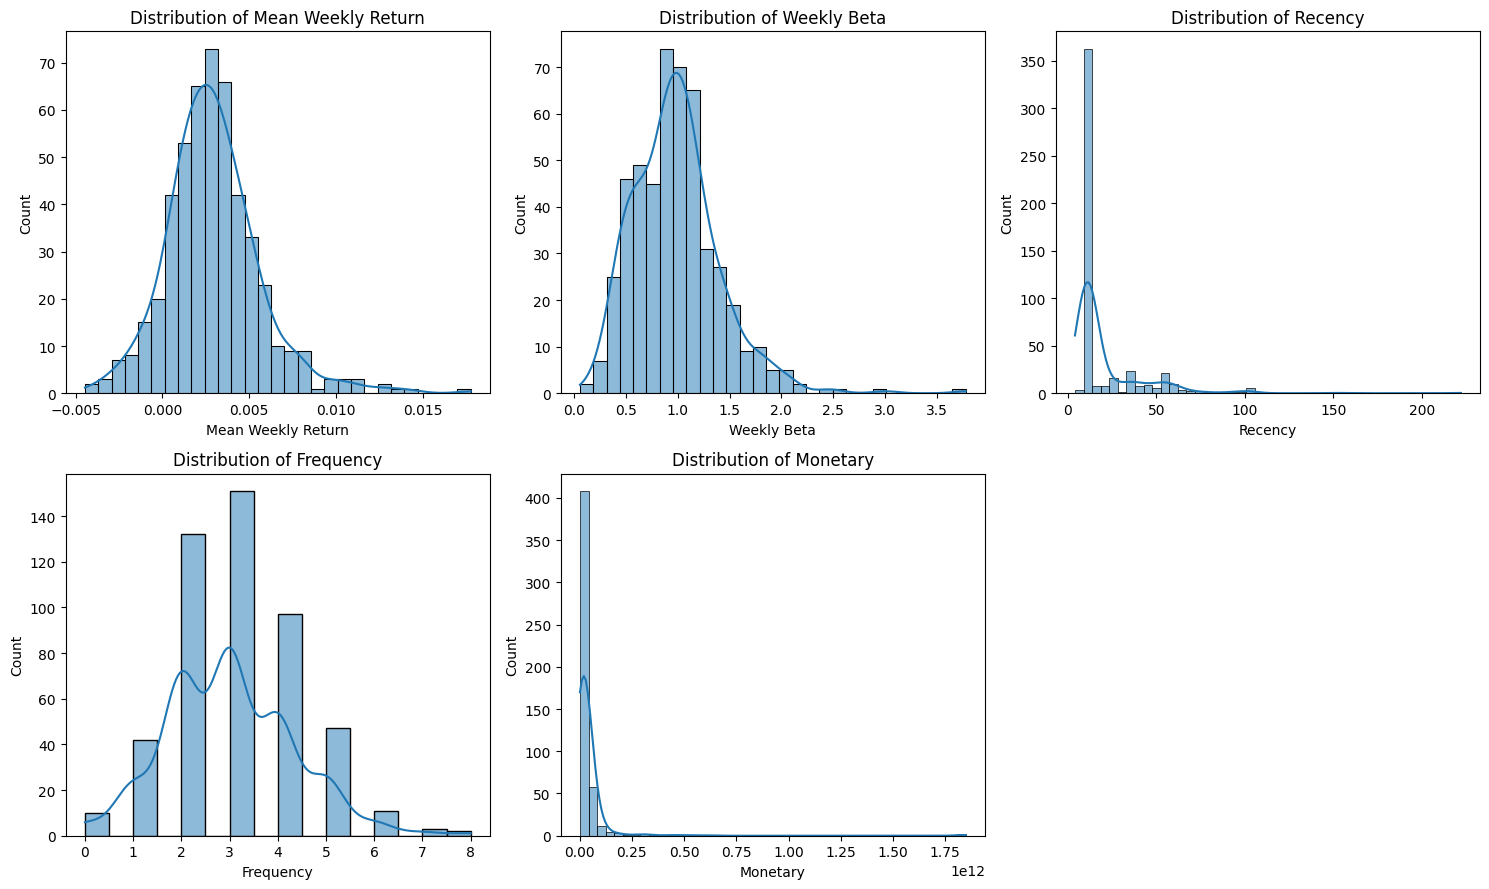

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualise feature distributions
features_to_plot = [
    'Mean Weekly Return',
    'Weekly Beta',
    'Recency',
    'Frequency',
    'Monetary'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), features_to_plot):

    sns.histplot(
        common_data[feature],
        kde=True,
        ax=ax
    )

    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)

# Remove unused subplot
fig.delaxes(axes.flatten()[5])

plt.tight_layout()
plt.show()

In [ ]:
#detect outliers
features_to_check = [
    'Mean Weekly Return',
    'Weekly Beta',
    'Recency',
    'Frequency',
    'Monetary'
]

outlier_results = []

for feature in features_to_check:

    Q1 = common_data[feature].quantile(0.25)
    Q3 = common_data[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = common_data[
        (common_data[feature] < lower_bound) |
        (common_data[feature] > upper_bound)
    ]

    outlier_results.append({
        'Feature': feature,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': len(outliers) / len(common_data) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print("IQR Outlier Analysis:")
display(outlier_summary.round(4))

IQR Outlier Analysis:


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Mean Weekly Return,-3.400000e-03,8.900000e-03,17,3.4343
1,Weekly Beta,-9.150000e-02,1.943800e+00,12,2.4242
2,Recency,5.000000e-01,2.850000e+01,97,19.5960
3,Frequency,-1.000000e+00,7.000000e+00,2,0.4040
4,Monetary,-2.323857e+10,6.606886e+10,47,9.4949


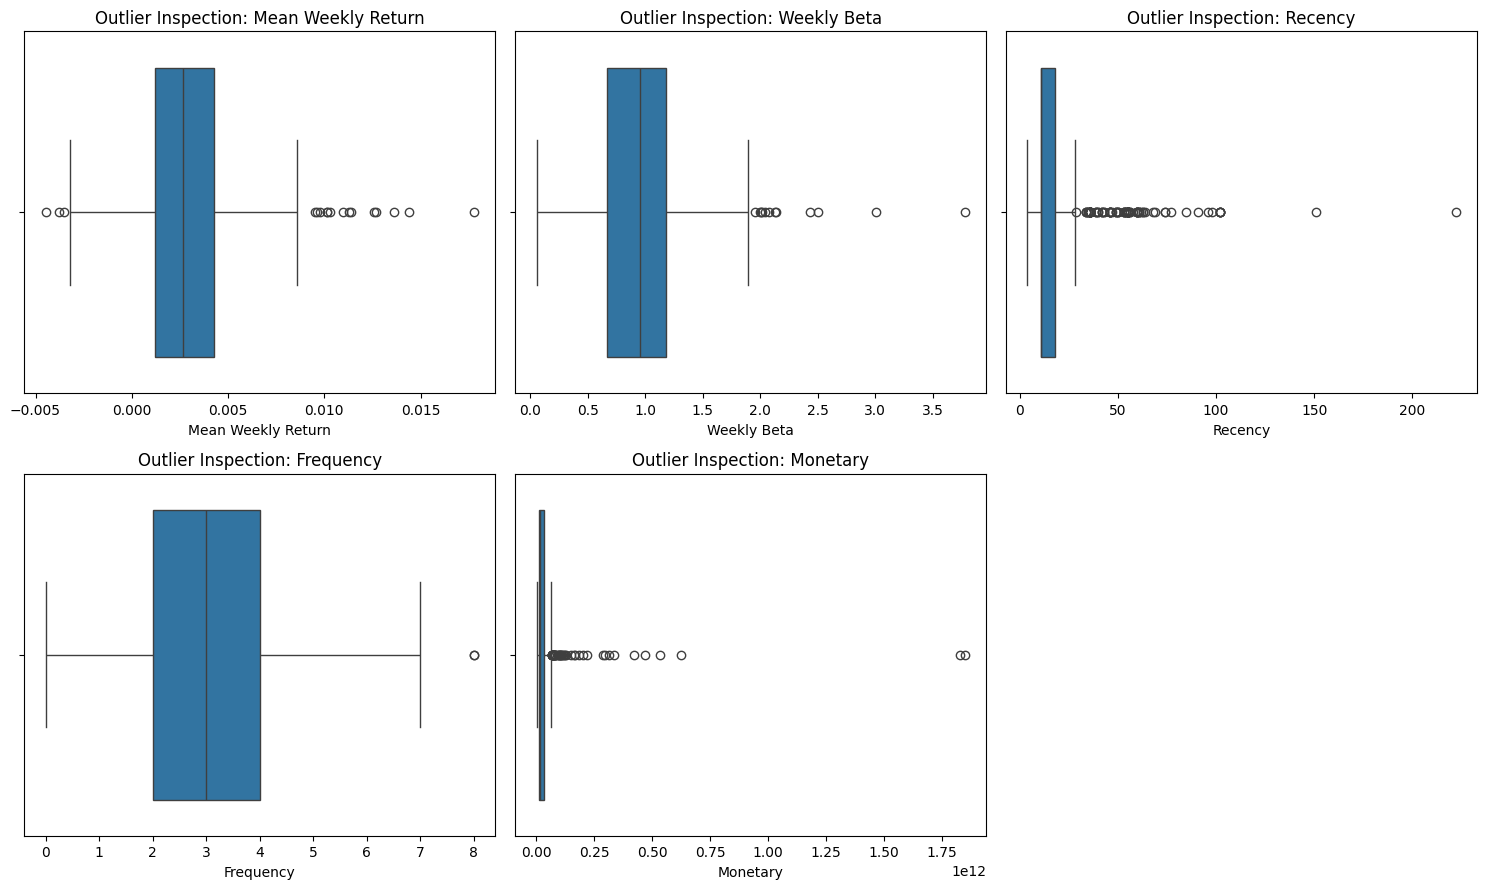

In [ ]:
#Python code – boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), features_to_check):

    sns.boxplot(
        x=common_data[feature],
        ax=ax
    )

    ax.set_title(f'Outlier Inspection: {feature}')

fig.delaxes(axes.flatten()[5])

plt.tight_layout()
plt.show()

In [ ]:
#2.1.4 Apply Log Transformation to Monetary
#transform Monetary
# Check that Monetary values are non-negative
if (rfm_features['Monetary'] < 0).any():
    raise ValueError("Monetary contains negative values.")

# Create a copy of the RFM matrix
rfm_transformed = rfm_features.copy()

# Apply log1p transformation to Monetary only
rfm_transformed['Monetary'] = np.log1p(
    rfm_transformed['Monetary']
)

print("RFM Features After Log Transformation:")
display(rfm_transformed.head())

# Compare Monetary skewness before and after transformation
monetary_skew_comparison = pd.DataFrame({
    'Before Transformation': [
        rfm_features['Monetary'].skew()
    ],
    'After log1p Transformation': [
        rfm_transformed['Monetary'].skew()
    ]
}, index=['Monetary'])

display(monetary_skew_comparison.round(4))

RFM Features After Log Transformation:


,Recency,Frequency,Monetary
0,11,2,23.362451
1,11,2,27.158299
2,11,3,24.948208
3,11,3,24.321359
4,11,1,24.285172


,Before Transformation,After log1p Transformation
Monetary,11.7073,1.0703


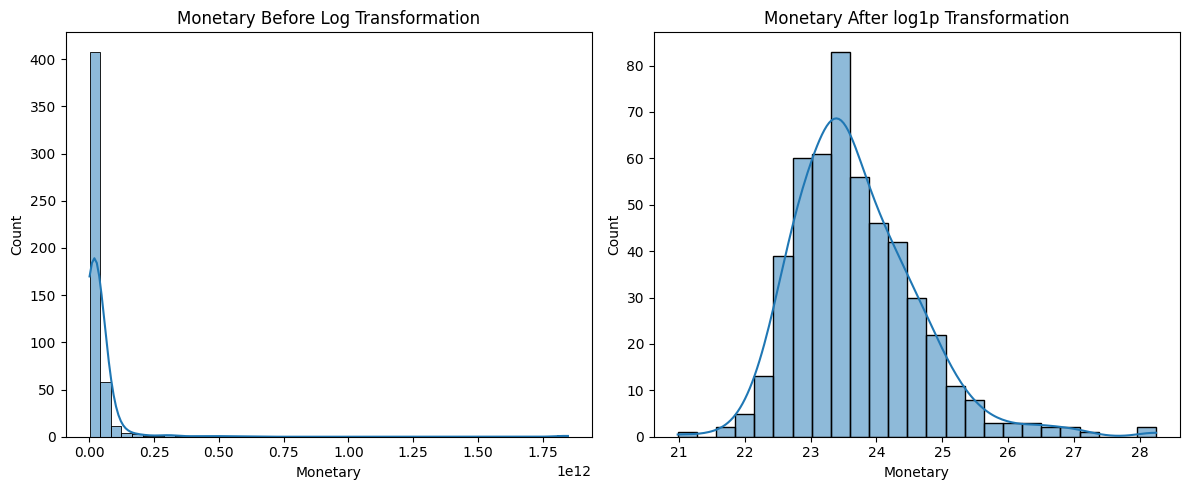

In [ ]:
#Visualise the transformation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    rfm_features['Monetary'],
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Monetary Before Log Transformation')

sns.histplot(
    rfm_transformed['Monetary'],
    kde=True,
    ax=axes[1]
)

axes[1].set_title('Monetary After log1p Transformation')

plt.tight_layout()
plt.show()

In [ ]:
#standardise both feature matrices
# Standardise Risk and Return features
risk_scaler = StandardScaler()

risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_features),
    columns=risk_features.columns,
    index=risk_features.index
)

# Standardise transformed RFM features separately
rfm_scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_transformed),
    columns=rfm_transformed.columns,
    index=rfm_transformed.index
)

print("Standardised Risk and Return Features:")
display(risk_scaled.head())

print("\nStandardised RFM Features:")
display(rfm_scaled.head())

# Check means and standard deviations
print("\nRisk and Return Standardisation Check:")
display(risk_scaled.agg(['mean', 'std']).round(4))

print("\nRFM Standardisation Check:")
display(rfm_scaled.agg(['mean', 'std']).round(4))

Standardised Risk and Return Features:


,Mean Weekly Return,Weekly Beta
0,-0.662530,0.220081
1,0.368654,0.458163
2,0.302346,-1.324200
3,-0.532269,1.166555
4,-0.717325,-0.948029



Standardised RFM Features:


,Recency,Frequency,Monetary
0,-0.44758,-0.753433,-0.346371
1,-0.44758,-0.753433,3.672982
2,-0.44758,0.000000,1.332757
3,-0.44758,0.000000,0.668998
4,-0.44758,-1.506865,0.630680



Risk and Return Standardisation Check:


,Mean Weekly Return,Weekly Beta
mean,0.000,0.000
std,1.001,1.001



RFM Standardisation Check:


,Recency,Frequency,Monetary
mean,-0.000,0.000,0.000
std,1.001,1.001,1.001


In [ ]:
#Final feature preparation summary
print("FINAL FEATURE PREPARATION SUMMARY")

print("\nNumber of common shares:", len(common_data))

print("\nRisk and Return Matrix:")
print(risk_scaled.shape)

print("\nTrading Activity RFM Matrix:")
print(rfm_scaled.shape)

print("\nMissing values in Risk and Return:")
print(risk_scaled.isnull().sum())

print("\nMissing values in RFM:")
print(rfm_scaled.isnull().sum())

FINAL FEATURE PREPARATION SUMMARY

Number of common shares: 495

Risk and Return Matrix:
(495, 2)

Trading Activity RFM Matrix:
(495, 3)

Missing values in Risk and Return:
Mean Weekly Return    0
Weekly Beta           0
dtype: int64

Missing values in RFM:
Recency      0
Frequency    0
Monetary     0
dtype: int64


# **Task 2.2**

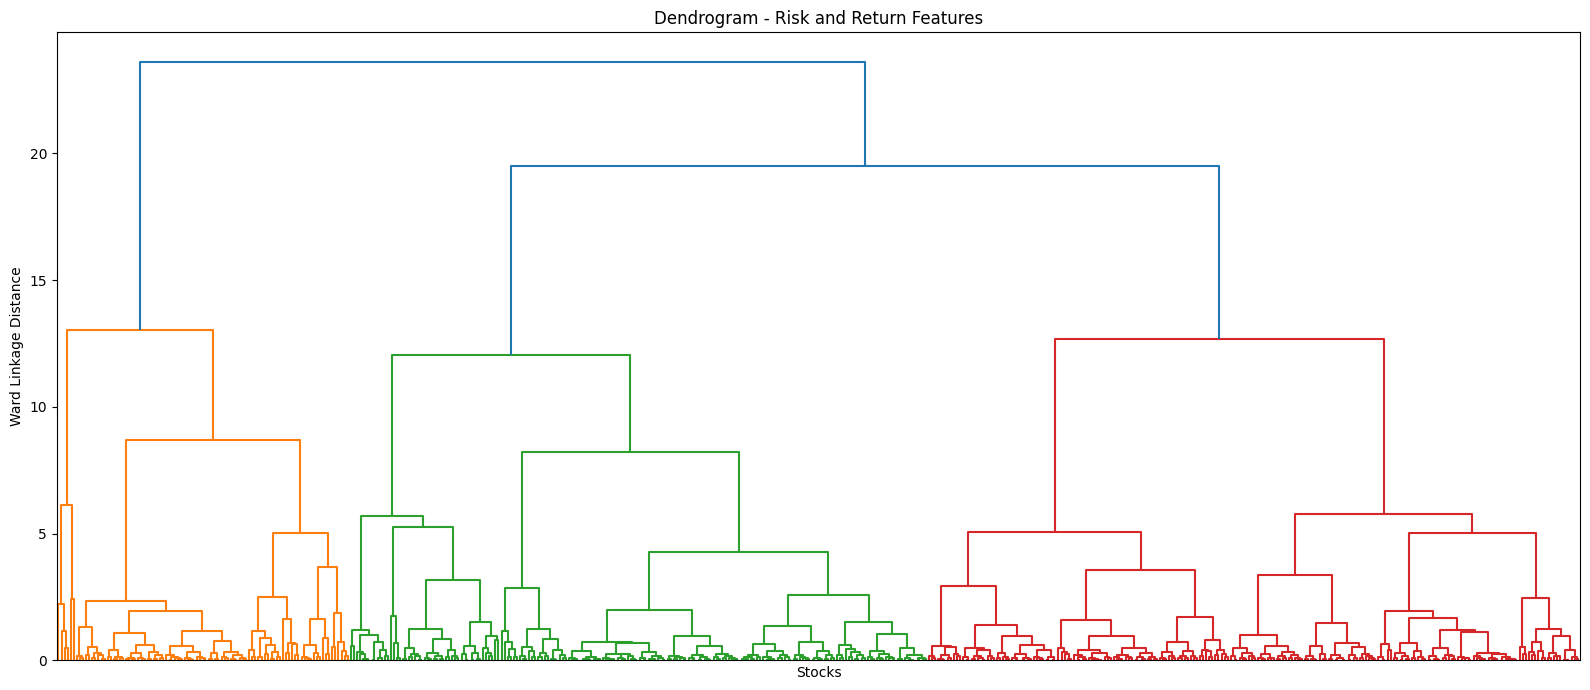

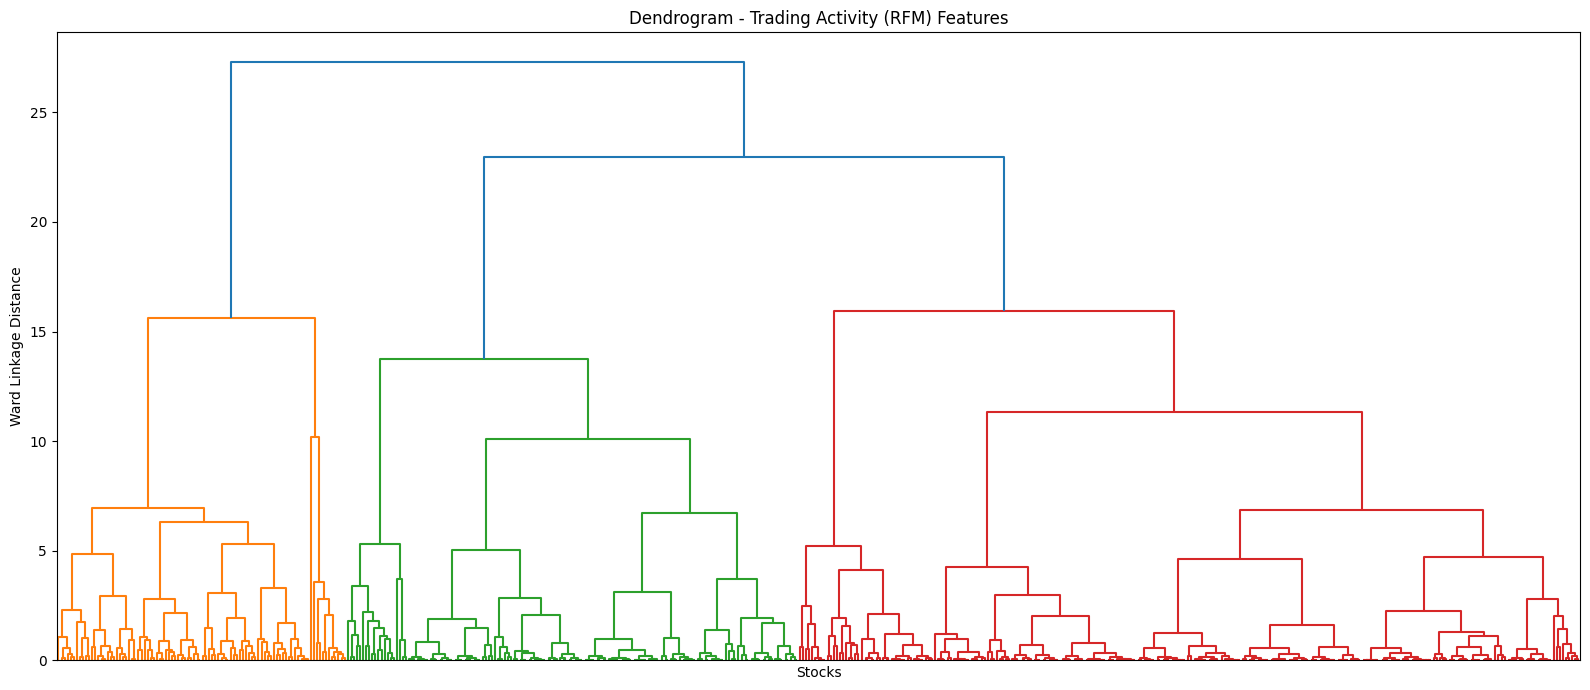

In [ ]:
#Task 2.2
# Import required libraries

from scipy.cluster.hierarchy import linkage, dendrogram

# Create Ward linkage matrices

risk_linkage = linkage(
    risk_scaled,
    method='ward',
    metric='euclidean'
)

rfm_linkage = linkage(
    rfm_scaled,
    method='ward',
    metric='euclidean'
)

# Risk and Return dendrogram

plt.figure(figsize=(16, 7))

dendrogram(
    risk_linkage,
    no_labels=True
)

plt.title('Dendrogram - Risk and Return Features')
plt.xlabel('Stocks')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()


# RFM dendrogram

plt.figure(figsize=(16, 7))

dendrogram(
    rfm_linkage,
    no_labels=True
)

plt.title('Dendrogram - Trading Activity (RFM) Features')
plt.xlabel('Stocks')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()

In [ ]:
#Evaluate cluster counts from 2 to 8
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Function to evaluate Agglomerative Clustering

def evaluate_agglomerative(data, dataset_name):

    results = []
    labels_dict = {}

    for k in range(2, 9):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='ward',
            metric='euclidean'
        )

        labels = model.fit_predict(data)

        # Calculate silhouette score
        score = silhouette_score(data, labels)

        # Calculate cluster sizes
        sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            'Clusters': k,
            'Silhouette Score': score,
            'Cluster Sizes': sizes.to_dict()
        })

        labels_dict[k] = labels

    results_df = pd.DataFrame(results)

    print(f'\n{dataset_name} - Agglomerative Clustering Results')
    display(results_df.round(4))

    return results_df, labels_dict


# Evaluate Risk and Return

risk_results, risk_labels = evaluate_agglomerative(
    risk_scaled,
    'Risk and Return'
)


# Evaluate RFM

rfm_results, rfm_labels = evaluate_agglomerative(
    rfm_scaled,
    'Trading Activity (RFM)'
)


Risk and Return - Agglomerative Clustering Results


,Clusters,Silhouette Score,Cluster Sizes
0,2,0.3501,"{0: 400, 1: 95}"
1,3,0.2844,"{0: 95, 1: 212, 2: 188}"
2,4,0.2911,"{0: 212, 1: 89, 2: 188, 3: 6}"
3,5,0.2723,"{0: 188, 1: 89, 2: 114, 3: 6, 4: 98}"
4,6,0.3006,"{0: 89, 1: 139, 2: 114, 3: 6, 4: 98, 5: 49}"
5,7,0.2960,"{0: 139, 1: 6, 2: 114, 3: 33, 4: 98, 5: 49, 6:..."
6,8,0.3130,"{0: 6, 1: 98, 2: 114, 3: 33, 4: 117, 5: 49, 6:..."



Trading Activity (RFM) - Agglomerative Clustering Results


,Clusters,Silhouette Score,Cluster Sizes
0,2,0.3584,"{0: 401, 1: 94}"
1,3,0.3080,"{0: 254, 1: 94, 2: 147}"
2,4,0.2923,"{0: 94, 1: 210, 2: 147, 3: 44}"
3,5,0.3115,"{0: 147, 1: 210, 2: 12, 3: 44, 4: 82}"
4,6,0.3201,"{0: 210, 1: 127, 2: 12, 3: 44, 4: 82, 5: 20}"
5,7,0.2991,"{0: 12, 1: 127, 2: 144, 3: 44, 4: 82, 5: 20, 6..."
6,8,0.3009,"{0: 127, 1: 82, 2: 144, 3: 44, 4: 11, 5: 20, 6..."


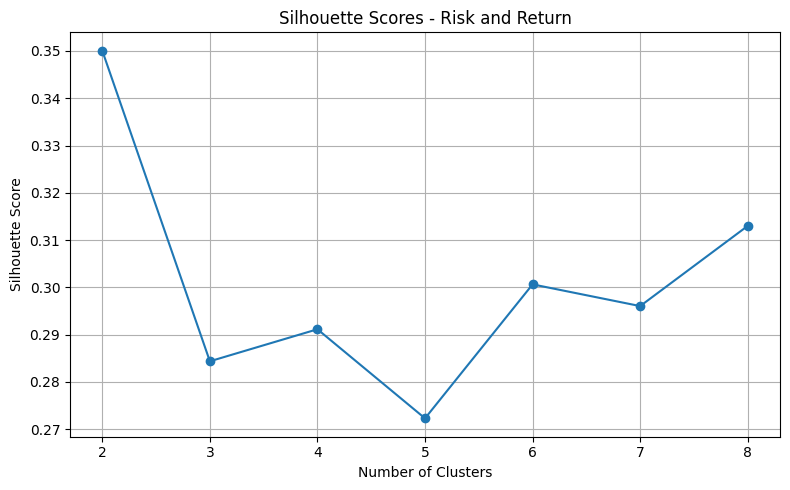

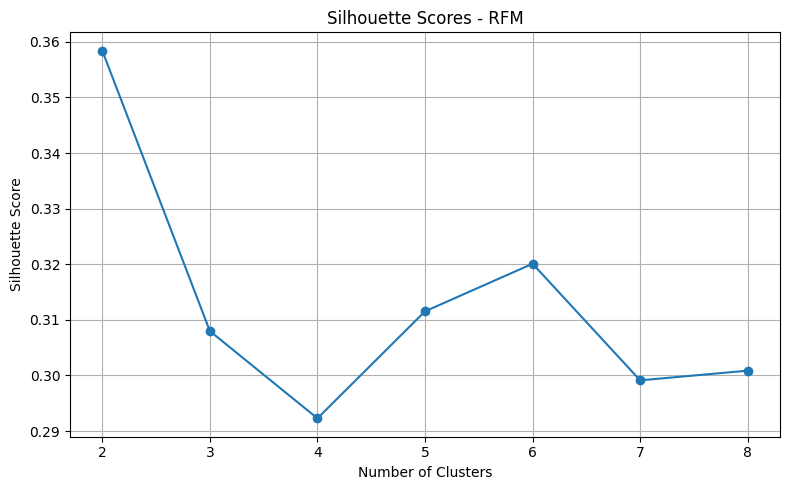

In [ ]:
#Compare silhouette scores visually
# Risk and Return silhouette scores

plt.figure(figsize=(8, 5))

plt.plot(
    risk_results['Clusters'],
    risk_results['Silhouette Score'],
    marker='o'
)

plt.title('Silhouette Scores - Risk and Return')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()


# RFM silhouette scores

plt.figure(figsize=(8, 5))

plt.plot(
    rfm_results['Clusters'],
    rfm_results['Silhouette Score'],
    marker='o'
)

plt.title('Silhouette Scores - RFM')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Select the number of clusters
# Enter the selected cluster counts based on your results

risk_best_k = 3   # Replace with your selected Risk and Return k
rfm_best_k = 4    # Replace with your selected RFM k


# Retrieve the cluster labels for the selected solutions

risk_selected_labels = risk_labels[risk_best_k]
rfm_selected_labels = rfm_labels[rfm_best_k]


# Display Risk and Return cluster sizes

risk_cluster_sizes = pd.Series(
    risk_selected_labels
).value_counts().sort_index()

print("Risk and Return - Selected Cluster Sizes")
display(risk_cluster_sizes)


# Display RFM cluster sizes

rfm_cluster_sizes = pd.Series(
    rfm_selected_labels
).value_counts().sort_index()

print("RFM - Selected Cluster Sizes")
display(rfm_cluster_sizes)

Risk and Return - Selected Cluster Sizes


,count
0,95
1,212
2,188


RFM - Selected Cluster Sizes


,count
0,94
1,210
2,147
3,44


In [ ]:
#Analyse the cluster profiles
# Create Risk and Return cluster profile dataset

risk_profile_data = risk_features.copy()

risk_profile_data['Ticker'] = common_data['Ticker'].values
risk_profile_data['Cluster'] = risk_selected_labels

# Calculate average feature values for each cluster

risk_profiles = risk_profile_data.groupby('Cluster').agg(
    Number_of_Stocks=('Ticker', 'count'),
    Mean_Weekly_Return=('Mean Weekly Return', 'mean'),
    Weekly_Beta=('Weekly Beta', 'mean')
)

print("Risk and Return Cluster Profiles")
display(risk_profiles.round(4))


# Create RFM cluster profile dataset

rfm_profile_data = rfm_features.copy()

rfm_profile_data['Ticker'] = common_data['Ticker'].values
rfm_profile_data['Cluster'] = rfm_selected_labels

# Calculate average feature values for each cluster

rfm_profiles = rfm_profile_data.groupby('Cluster').agg(
    Number_of_Stocks=('Ticker', 'count'),
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary=('Monetary', 'mean')
)

print("RFM Cluster Profiles")
display(rfm_profiles.round(2))

Risk and Return Cluster Profiles


,Number_of_Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,95,0.0065,1.3259
1,212,0.0025,0.6361
2,188,0.0016,1.1988


RFM Cluster Profiles


,Number_of_Stocks,Recency,Frequency,Monetary
Cluster,,,,
0,94,55.53,2.07,4.565006e+10
1,210,11.14,2.95,1.113269e+10
2,147,12.70,2.96,8.393315e+10
3,44,16.70,5.36,1.481576e+10


# **Task 2.3**

In [ ]:
#Task 2.3
#Evaluate different cluster counts

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

def evaluate_kmeans(data):
    results = []
    labels_dict = {}

    for k in range(2, 9):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(data)
        silhouette = silhouette_score(data, labels)
        sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            'K': k,
            'Silhouette Score': round(silhouette, 4),
            'Inertia': round(model.inertia_, 2),
            'Cluster Sizes': sizes.to_dict()
        })

        labels_dict[k] = labels

    return pd.DataFrame(results), labels_dict


# Risk and Return
risk_kmeans_results, risk_kmeans_labels = evaluate_kmeans(risk_scaled)

# RFM
rfm_kmeans_results, rfm_kmeans_labels = evaluate_kmeans(rfm_scaled)

print("Risk and Return K-means Results")
display(risk_kmeans_results)

print("RFM K-means Results")
display(rfm_kmeans_results)

Risk and Return K-means Results


,K,Silhouette Score,Inertia,Cluster Sizes
0,2,0.3903,631.09,"{0: 349, 1: 146}"
1,3,0.3186,477.82,"{0: 121, 1: 167, 2: 207}"
2,4,0.3240,376.94,"{0: 154, 1: 129, 2: 40, 3: 172}"
3,5,0.3370,315.45,"{0: 155, 1: 23, 2: 129, 3: 133, 4: 55}"
4,6,0.3381,264.58,"{0: 128, 1: 47, 2: 166, 3: 7, 4: 107, 5: 40}"
5,7,0.3322,227.12,"{0: 87, 1: 50, 2: 143, 3: 7, 4: 92, 5: 75, 6: 41}"
6,8,0.3531,194.85,"{0: 76, 1: 44, 2: 40, 3: 7, 4: 78, 5: 81, 6: 3..."


RFM K-means Results


,K,Silhouette Score,Inertia,Cluster Sizes
0,2,0.4186,1087.23,"{0: 72, 1: 423}"
1,3,0.3247,813.71,"{0: 65, 1: 275, 2: 155}"
2,4,0.3415,620.93,"{0: 215, 1: 124, 2: 61, 3: 95}"
3,5,0.3579,524.81,"{0: 124, 1: 201, 2: 11, 3: 70, 4: 89}"
4,6,0.3461,445.03,"{0: 70, 1: 42, 2: 144, 3: 122, 4: 11, 5: 106}"
5,7,0.3493,393.87,"{0: 121, 1: 104, 2: 71, 3: 42, 4: 145, 5: 11, ..."
6,8,0.3472,350.47,"{0: 20, 1: 141, 2: 66, 3: 108, 4: 11, 5: 67, 6..."


In [ ]:
#Generate cluster profiles
# Replace these after reviewing the evaluation results
risk_kmeans_best_k = 3
rfm_kmeans_best_k = 4

# Risk and Return profiles
risk_kmeans_profile = risk_features.copy()
risk_kmeans_profile['Ticker'] = common_data['Ticker'].values
risk_kmeans_profile['Cluster'] = risk_kmeans_labels[risk_kmeans_best_k]

risk_kmeans_profiles = risk_kmeans_profile.groupby('Cluster').agg(
    Number_of_Stocks=('Ticker', 'count'),
    Mean_Weekly_Return=('Mean Weekly Return', 'mean'),
    Weekly_Beta=('Weekly Beta', 'mean')
).round(4)

display(risk_kmeans_profiles)


# RFM profiles
rfm_kmeans_profile = rfm_features.copy()
rfm_kmeans_profile['Ticker'] = common_data['Ticker'].values
rfm_kmeans_profile['Cluster'] = rfm_kmeans_labels[rfm_kmeans_best_k]

rfm_kmeans_profiles = rfm_kmeans_profile.groupby('Cluster').agg(
    Number_of_Stocks=('Ticker', 'count'),
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary=('Monetary', 'mean')
).round(2)

display(rfm_kmeans_profiles)

,Number_of_Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,121,0.0061,1.3550
1,167,0.0010,1.1388
2,207,0.0026,0.6379


,Number_of_Stocks,Recency,Frequency,Monetary
Cluster,,,,
0,215,13.28,2.37,1.516509e+10
1,124,13.90,4.55,1.496389e+10
2,61,66.05,1.64,5.618444e+10
3,95,16.36,3.27,1.165870e+11


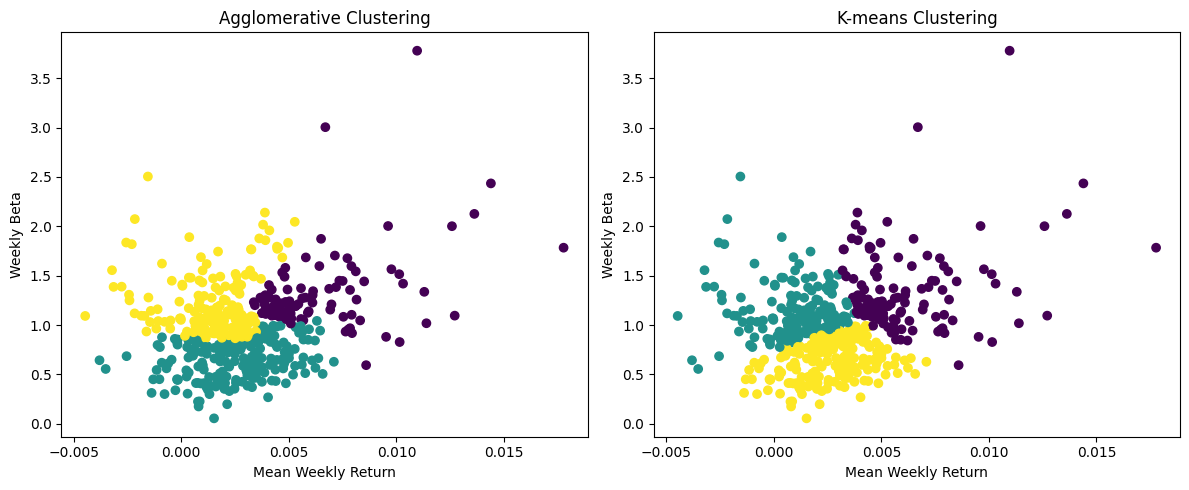

PCA explained variance: 0.7954


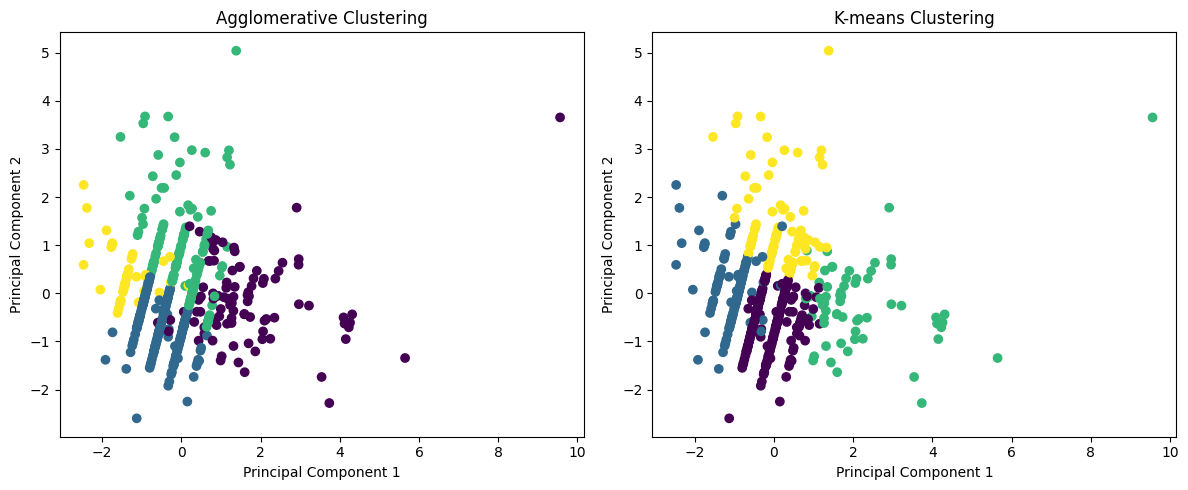

,Dataset,Adjusted Rand Index
0,Risk and Return,0.5885
1,RFM,0.3495


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Selected cluster labels
risk_agg_labels = risk_selected_labels
rfm_agg_labels = rfm_selected_labels

risk_km_labels = risk_kmeans_labels[3]
rfm_km_labels = rfm_kmeans_labels[4]

# 1. Risk and Return visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    risk_features['Mean Weekly Return'],
    risk_features['Weekly Beta'],
    c=risk_agg_labels
)
axes[0].set_title('Agglomerative Clustering')
axes[0].set_xlabel('Mean Weekly Return')
axes[0].set_ylabel('Weekly Beta')

axes[1].scatter(
    risk_features['Mean Weekly Return'],
    risk_features['Weekly Beta'],
    c=risk_km_labels
)
axes[1].set_title('K-means Clustering')
axes[1].set_xlabel('Mean Weekly Return')
axes[1].set_ylabel('Weekly Beta')

plt.tight_layout()
plt.show()


# 2. RFM visualisation using PCA
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

print("PCA explained variance:",
      pca.explained_variance_ratio_.sum().round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    rfm_pca[:, 0], rfm_pca[:, 1],
    c=rfm_agg_labels
)
axes[0].set_title('Agglomerative Clustering')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

axes[1].scatter(
    rfm_pca[:, 0], rfm_pca[:, 1],
    c=rfm_km_labels
)
axes[1].set_title('K-means Clustering')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()


# 3. Compare algorithm assignments using ARI
comparison = pd.DataFrame({
    'Dataset': ['Risk and Return', 'RFM'],
    'Adjusted Rand Index': [
        adjusted_rand_score(risk_agg_labels, risk_km_labels),
        adjusted_rand_score(rfm_agg_labels, rfm_km_labels)
    ]
})

display(comparison.round(4))

# **Task 2.5**

In [ ]:
#Task 2.5
#2.5.1 Correlation analysis
# Correlation between R, F and log1p(M)
rfm_corr = rfm_transformed[
    ['Recency', 'Frequency', 'Monetary']
].corr()

display(rfm_corr.round(4))

,Recency,Frequency,Monetary
Recency,1.0000,-0.3413,0.1639
Frequency,-0.3413,1.0000,0.0188
Monetary,0.1639,0.0188,1.0000


In [ ]:
#Task 2.5.2

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Prepare and standardise Recency and Frequency afresh
rf_features = rfm_features[['Recency', 'Frequency']]

rf_scaled = StandardScaler().fit_transform(rf_features)

# Apply Ward clustering using the same four clusters
rf_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward',
    metric='euclidean'
)

rf_labels = rf_model.fit_predict(rf_scaled)

# Compare cluster memberships
ari = adjusted_rand_score(rfm_selected_labels, rf_labels)

print("Adjusted Rand Index:", round(ari, 4))


# Compare traded value (Monetary) profiles
comparison_data = pd.DataFrame({
    'Original_RFM_Cluster': rfm_selected_labels,
    'Reduced_RF_Cluster': rf_labels,
    'Monetary': rfm_features['Monetary'].values
})

print("Original RFM Monetary Profiles")
display(
    comparison_data.groupby('Original_RFM_Cluster').agg(
        Number_of_Stocks=('Monetary', 'count'),
        Average_Traded_Value=('Monetary', 'mean')
    ).round(2)
)

print("Reduced R-F Monetary Profiles")
display(
    comparison_data.groupby('Reduced_RF_Cluster').agg(
        Number_of_Stocks=('Monetary', 'count'),
        Average_Traded_Value=('Monetary', 'mean')
    ).round(2)
)

Adjusted Rand Index: 0.2372
Original RFM Monetary Profiles


,Number_of_Stocks,Average_Traded_Value
Original_RFM_Cluster,,
0,94,4.565006e+10
1,210,1.113269e+10
2,147,8.393315e+10
3,44,1.481576e+10


Reduced R-F Monetary Profiles


,Number_of_Stocks,Average_Traded_Value
Reduced_RF_Cluster,,
0,277,3.921707e+10
1,10,1.997420e+11
2,125,3.433790e+10
3,83,2.971388e+10


# **Task 3**

Task 3.1


In [ ]:

import sqlite3

# Create the database
conn = sqlite3.connect("stock_market_datamart.db")
cursor = conn.cursor()

# ==========================================
# 1. DIMENSION TABLES
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS DimDate (
    DateKey INTEGER PRIMARY KEY,
    ObservationDate DATE,
    Day INTEGER,
    Month INTEGER,
    Quarter INTEGER,
    Year INTEGER,
    TradingDay INTEGER
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS DimSector (
    SectorKey INTEGER PRIMARY KEY,
    SectorName TEXT
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS DimShare (
    ShareKey INTEGER PRIMARY KEY,
    Ticker TEXT,
    CompanyName TEXT,
    SectorKey INTEGER,
    FOREIGN KEY (SectorKey) REFERENCES DimSector(SectorKey)
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS DimBenchmark (
    BenchmarkKey INTEGER PRIMARY KEY,
    BenchmarkName TEXT,
    BenchmarkTicker TEXT
)
""")

# ==========================================
# 2. DAILY MARKET FACT TABLE
# Grain: One share per trading date
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS FactDailyMarket (
    DateKey INTEGER,
    ShareKey INTEGER,
    BenchmarkKey INTEGER,
    OpenPrice REAL,
    HighPrice REAL,
    LowPrice REAL,
    ClosePrice REAL,
    AdjustedClose REAL,
    TradingVolume INTEGER,
    DailyReturn REAL,
    BenchmarkDailyReturn REAL,
    SourceName TEXT,
    RetrievalDate DATE,
    PRIMARY KEY (DateKey, ShareKey, BenchmarkKey),
    FOREIGN KEY (DateKey) REFERENCES DimDate(DateKey),
    FOREIGN KEY (ShareKey) REFERENCES DimShare(ShareKey),
    FOREIGN KEY (BenchmarkKey) REFERENCES DimBenchmark(BenchmarkKey)
)
""")

# ==========================================
# 3. DERIVED SHARE METRICS FACT TABLE
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS FactShareMetrics (
    ShareKey INTEGER,
    BenchmarkKey INTEGER,
    PeriodStartDate DATE,
    PeriodEndDate DATE,
    CalculationVersion TEXT,
    MeanWeeklyReturn REAL,
    WeeklyBeta REAL,
    Recency REAL,
    Frequency REAL,
    Monetary REAL,
    PRIMARY KEY (
        ShareKey, BenchmarkKey, PeriodStartDate,
        PeriodEndDate, CalculationVersion
    ),
    FOREIGN KEY (ShareKey) REFERENCES DimShare(ShareKey),
    FOREIGN KEY (BenchmarkKey) REFERENCES DimBenchmark(BenchmarkKey)
)
""")

# ==========================================
# 4. CLUSTER ASSIGNMENT FACT TABLE
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS FactClusterAssignment (
    ShareKey INTEGER,
    ModelRunID TEXT,
    Algorithm TEXT,
    FeatureSet TEXT,
    ClusterCount INTEGER,
    ClusterID INTEGER,
    RandomSeed INTEGER,
    CalculationVersion TEXT,
    PRIMARY KEY (ShareKey, ModelRunID),
    FOREIGN KEY (ShareKey) REFERENCES DimShare(ShareKey)
)
""")

# ==========================================
# 5. MODEL RUN HISTORY
# ==========================================

cursor.execute("""
CREATE TABLE IF NOT EXISTS DimModelRun (
    ModelRunID TEXT PRIMARY KEY,
    Algorithm TEXT,
    FeatureSet TEXT,
    FeatureWindowStart DATE,
    FeatureWindowEnd DATE,
    ObservationDate DATE,
    ClusterCount INTEGER,
    LinkageMethod TEXT,
    DistanceMetric TEXT,
    RandomSeed INTEGER,
    CalculationVersion TEXT
)
""")

# Save changes
conn.commit()

print("Stock Market Data Mart created successfully!")

# Display created tables
cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table'
ORDER BY name
""")

tables = cursor.fetchall()

print("\nCreated Tables:")
for table in tables:
    print("-", table[0])

conn.close()


Stock Market Data Mart created successfully!

Created Tables:
- DimBenchmark
- DimDate
- DimModelRun
- DimSector
- DimShare
- FactClusterAssignment
- FactDailyMarket
- FactShareMetrics


In [ ]:

import sqlite3

conn = sqlite3.connect("stock_market_datamart.db")
cursor = conn.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""")

for (table_name,) in cursor.fetchall():
    print(f"\n--- {table_name} ---")

    cursor.execute(f"PRAGMA table_info({table_name})")

    for column in cursor.fetchall():
        print(column[1], "-", column[2])

conn.close()



--- DimBenchmark ---
BenchmarkKey - INTEGER
BenchmarkName - TEXT
BenchmarkTicker - TEXT

--- DimDate ---
DateKey - INTEGER
ObservationDate - DATE
Day - INTEGER
Month - INTEGER
Quarter - INTEGER
Year - INTEGER
TradingDay - INTEGER

--- DimModelRun ---
ModelRunID - TEXT
Algorithm - TEXT
FeatureSet - TEXT
FeatureWindowStart - DATE
FeatureWindowEnd - DATE
ObservationDate - DATE
ClusterCount - INTEGER
LinkageMethod - TEXT
DistanceMetric - TEXT
RandomSeed - INTEGER
CalculationVersion - TEXT

--- DimSector ---
SectorKey - INTEGER
SectorName - TEXT

--- DimShare ---
ShareKey - INTEGER
Ticker - TEXT
CompanyName - TEXT
SectorKey - INTEGER

--- FactClusterAssignment ---
ShareKey - INTEGER
ModelRunID - TEXT
Algorithm - TEXT
FeatureSet - TEXT
ClusterCount - INTEGER
ClusterID - INTEGER
RandomSeed - INTEGER
CalculationVersion - TEXT

--- FactDailyMarket ---
DateKey - INTEGER
ShareKey - INTEGER
BenchmarkKey - INTEGER
OpenPrice - REAL
HighPrice - REAL
LowPrice - REAL
ClosePrice - REAL
AdjustedClose - 

# Task 3.2

Task 3.2.1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the selected K-means cluster labels
risk_cluster_labels = risk_kmeans_labels[3]
rfm_cluster_labels = rfm_kmeans_labels[4]

# Risk and Return cluster profiles
risk_profile = risk_features.copy()
risk_profile["Ticker"] = common_data["Ticker"].values
risk_profile["Cluster"] = risk_cluster_labels

risk_summary = risk_profile.groupby("Cluster").agg(
    Number_of_Stocks=("Ticker", "count"),
    Mean_Weekly_Return=("Mean Weekly Return", "mean"),
    Average_Weekly_Beta=("Weekly Beta", "mean")
)

print("Risk and Return Cluster Profiles")
display(risk_summary.round(4))


# RFM cluster profiles
rfm_profile = rfm_features.copy()
rfm_profile["Ticker"] = common_data["Ticker"].values
rfm_profile["Cluster"] = rfm_cluster_labels

rfm_summary = rfm_profile.groupby("Cluster").agg(
    Number_of_Stocks=("Ticker", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
)

print("RFM Cluster Profiles")
display(rfm_summary.round(2))

Risk and Return Cluster Profiles


,Number_of_Stocks,Mean_Weekly_Return,Average_Weekly_Beta
Cluster,,,
0,121,0.0061,1.3550
1,167,0.0010,1.1388
2,207,0.0026,0.6379


RFM Cluster Profiles


,Number_of_Stocks,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,215,13.28,2.37,1.516509e+10
1,124,13.90,4.55,1.496389e+10
2,61,66.05,1.64,5.618444e+10
3,95,16.36,3.27,1.165870e+11


In [ ]:
#Analyse sector composition
# Prepare sector information
sector_data = sp500[["Symbol", "GICS Sector"]].copy()

sector_data.columns = ["Ticker", "Sector"]

sector_data["Ticker"] = sector_data["Ticker"].str.replace(
    ".", "-", regex=False
)

sector_data = sector_data.drop_duplicates(subset="Ticker")


# Combine ticker and cluster information
sector_results = pd.DataFrame({
    "Ticker": common_data["Ticker"].values,
    "Risk_Cluster": risk_cluster_labels,
    "RFM_Cluster": rfm_cluster_labels
})

sector_results = sector_results.merge(
    sector_data,
    on="Ticker",
    how="left"
)

print("Missing sector values:", sector_results["Sector"].isna().sum())


# Risk and Return sector composition
risk_sector = pd.crosstab(
    sector_results["Risk_Cluster"],
    sector_results["Sector"]
)

print("Risk and Return Sector Composition")
display(risk_sector)


# RFM sector composition
rfm_sector = pd.crosstab(
    sector_results["RFM_Cluster"],
    sector_results["Sector"]
)

print("RFM Sector Composition")
display(rfm_sector)

Missing sector values: 0
Risk and Return Sector Composition


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Risk_Cluster,,,,,,,,,,,
0,6,17,1,8,15,2,23,39,4,3,3
1,4,18,5,0,27,27,29,32,11,12,2
2,11,12,26,13,34,30,28,3,9,15,26


RFM Sector Composition


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RFM_Cluster,,,,,,,,,,,
0,4,20,13,15,34,19,44,24,12,18,12
1,6,9,7,1,19,20,25,12,5,12,8
2,2,7,5,1,8,6,4,13,5,0,10
3,9,11,7,4,15,14,7,25,2,0,1


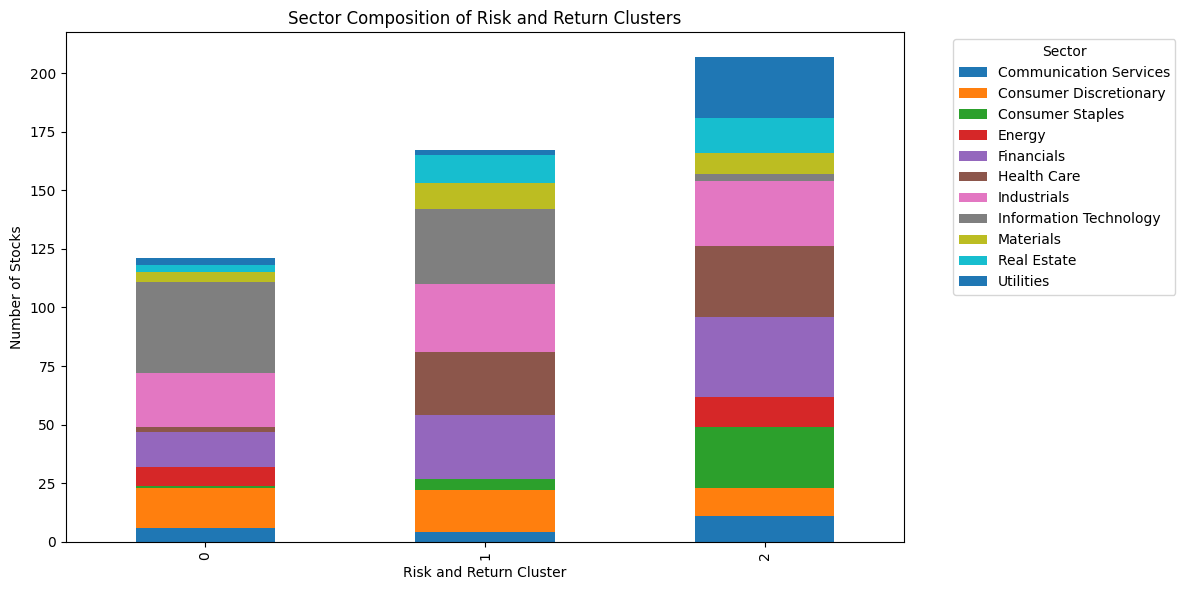

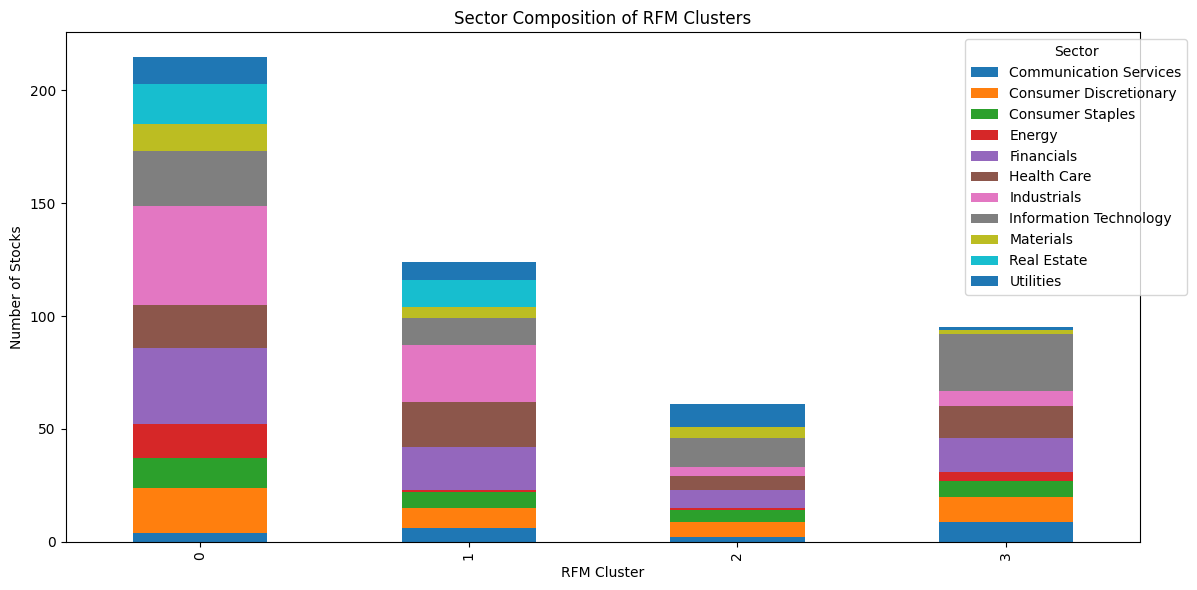

In [ ]:
#Create sector composition charts
# Risk and Return sector composition chart
risk_sector.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Sector Composition of Risk and Return Clusters")
plt.xlabel("Risk and Return Cluster")
plt.ylabel("Number of Stocks")
plt.legend(title="Sector", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


# RFM sector composition chart
rfm_sector.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Sector Composition of RFM Clusters")
plt.xlabel("RFM Cluster")
plt.ylabel("Number of Stocks")
plt.legend(title="Sector", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# **Task 3.2.2**

In [ ]:
#Display the correlation between RFM variables
# Correlation between RFM variables
rfm_correlation = rfm_transformed[
    ["Recency", "Frequency", "Monetary"]
].corr()

print("Correlation Matrix of RFM Variables")
display(rfm_correlation.round(4))


Correlation Matrix of RFM Variables


,Recency,Frequency,Monetary
Recency,1.0000,-0.3413,0.1639
Frequency,-0.3413,1.0000,0.0188
Monetary,0.1639,0.0188,1.0000


In [ ]:
#Compare the original and reduced RFM clusters
from sklearn.metrics import adjusted_rand_score

# Compare original RFM clusters with reduced R-F clusters
ari_score = adjusted_rand_score(
    rfm_selected_labels,
    rf_labels
)

print("Adjusted Rand Index:", round(ari_score, 4))

Adjusted Rand Index: 0.2372


In [ ]:
#Compare average Monetary values
# Original RFM cluster monetary profiles
original_monetary = pd.DataFrame({
    "Cluster": rfm_selected_labels,
    "Monetary": rfm_features["Monetary"].values
})

original_summary = original_monetary.groupby("Cluster").agg(
    Number_of_Stocks=("Monetary", "count"),
    Average_Monetary=("Monetary", "mean")
).round(2)

print("Original RFM Monetary Profiles")
display(original_summary)

# Reduced R-F cluster monetary profiles
reduced_monetary = pd.DataFrame({
    "Cluster": rf_labels,
    "Monetary": rfm_features["Monetary"].values
})

reduced_summary = reduced_monetary.groupby("Cluster").agg(
    Number_of_Stocks=("Monetary", "count"),
    Average_Monetary=("Monetary", "mean")
).round(2)

print("Reduced R-F Monetary Profiles")
display(reduced_summary)

Original RFM Monetary Profiles


,Number_of_Stocks,Average_Monetary
Cluster,,
0,94,4.565006e+10
1,210,1.113269e+10
2,147,8.393315e+10
3,44,1.481576e+10


Reduced R-F Monetary Profiles


,Number_of_Stocks,Average_Monetary
Cluster,,
0,277,3.921707e+10
1,10,1.997420e+11
2,125,3.433790e+10
3,83,2.971388e+10
